# Why This Action? — 04 · Grafo sin orden dado, conformal bajo intervención y robustez del buscador

Cierra los pendientes de los cuadernos anteriores sobre el ejemplo perioperatorio lineal.

| § | Pendiente que cierra | Qué se añade |
|---|---|---|
| 1 | "El orden causal lo da el experto" | Búsqueda exacta del grafo sobre **todos** los órdenes, con bootstrap, y tres niveles de conocimiento previo |
| 2 | ¿Cuánto cuesta no conocer el orden? | El plan robusto con cada nivel: costo y éxito real |
| 3 | "Conformal solo vale sin intervenir" | Conformal **localizado** en el punto al que lleva el plan, comprobado bajo la intervención |
| 4 | El caso malo del buscador (cuaderno 02) | Brecha frente al óptimo con tres variantes del buscador, en 12 pacientes |
| 5 | "24 casos no distinguen 90 % de 100 %" | 45 casos con intervalo de confianza |

Todo es simulación sobre el ejemplo sintético. Usa `wta_core.py`.

## 0 · Preparación

In [1]:
import numpy as np, matplotlib.pyplot as plt, time
from wta_core import *
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
prob = Problem()
def pick_patients(n, rng):
    pool = sample_world(40 * n, rng); m = prob.blackbox().margin(pool)
    return pool[(m < -1.0) & (m > -2.2)][:n]
def true_success(x, plan): return float(prob.blackbox().margin(counterfactual(x, TRUE_WORLD, plan[None])[0])[0] >= 0)
def wilson(k, n, z=1.96):
    p = k / n; c = (p + z * z / (2 * n)) / (1 + z * z / n); h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return max(0, c - h), min(1, c + h)
TRUE_G = frozenset(TRUE_EDGES)

## 1 · Descubrir el grafo sin que nadie dé el orden

**Qué hace.** Reemplaza el supuesto de los cuadernos 01 y 02. Para cada remuestreo busca el mejor grafo según BIC entre **todos los órdenes posibles** (búsqueda exacta, posible porque son 5 variables). Si varios grafos empatan, el peso se reparte entre ellos: con datos gaussianos, los grafos de una misma clase de equivalencia de Markov son indistinguibles.

Compara tres niveles de conocimiento previo:
1. el experto da el orden completo (lo que había);
2. solo se sabe que nada causa la edad;
3. no se sabe nada.

**Literatura**
- *Your Assumed DAG is Wrong and Here's How To Deal With It* (Padh y otros, 2025). *Solo resumen.*
- *Confidence Sets for Causal Orderings* (Wang, Kolar, Drton, 2023). *Pendiente de leer.*
- *DiBS* (Lorch y otros, NeurIPS 2021): alternativa bayesiana para más variables. *Pendiente de leer.*
- Posición 2026 (Karimi): **§4.1** y **§5.1**, identificabilidad y descubrimiento causal robusto.

**Gap declarado.** NeurIPS 2020 (§8) y MINT (§6) suponen el grafo conocido. La posición de 2026 lista la identificabilidad como obstáculo.

**Cómo leer el código.** `best_dags` y `bootstrap_dags` están en `wta_core.py`. `forbidden` es la lista de flechas que el experto descarta.

**Qué mirar.** Cuánto peso se va a grafos con alguna flecha verdadera invertida cuando se quita conocimiento previo.

In [2]:
LEVELS = [("Orden completo dado por el experto", None),
          ("Solo se sabe que nada causa la edad", [(v, "Age") for v in VARS[1:]]),
          ("Sin ningún conocimiento previo", [])]
rng = np.random.default_rng(50); X_obs = sample_world(300, rng)
print("Con un conjunto de 300 datos y 100 remuestreos:\n")
for nm, fb in LEVELS:
    G = bootstrap_graphs(X_obs, B=100, rng=rng) if fb is None else bootstrap_dags(X_obs, B=100, rng=rng, forbidden=fb)
    w_true = sum(w for g, w in G if g == TRUE_G)
    rev = sum(w for g, w in G if any((j, k) in g for (k, j) in TRUE_EDGES))        # alguna flecha verdadera al revés
    print(f"{nm:<40} grafos distintos: {len(G):>3} | peso del grafo verdadero: {w_true:.2f} | peso de grafos con alguna flecha invertida: {rev:.2f}")

Con un conjunto de 300 datos y 100 remuestreos:

Orden completo dado por el experto       grafos distintos:  14 | peso del grafo verdadero: 0.58 | peso de grafos con alguna flecha invertida: 0.00


Solo se sabe que nada causa la edad      grafos distintos:  22 | peso del grafo verdadero: 0.48 | peso de grafos con alguna flecha invertida: 0.31


Sin ningún conocimiento previo           grafos distintos:  63 | peso del grafo verdadero: 0.44 | peso de grafos con alguna flecha invertida: 0.39


## 2 · ¿Cuánto cuesta no conocer el orden?

**Qué hace.** Para 6 conjuntos de datos y 3 pacientes busca el plan robusto (riesgo 10 %) con las versiones del modelo causal que salen de cada nivel de conocimiento, y mide costo y éxito real.

**Cómo leer el código.** Con grafos de cualquier orden, el contrafactual se calcula con varias pasadas (`sample_worlds_general` marca las versiones con `sweeps = 5`). En una versión donde la flecha Hb → SBP no existe o está invertida, bloquearla no hace nada.

**Qué mirar.** Si el plan sigue funcionando en el mundo verdadero y cuánto sube el costo, o si deja de existir plan, al tener que cubrir grafos con flechas invertidas.

In [3]:
rows = []; t0 = time.time()
for d in range(6):
    rng = np.random.default_rng(200 + d); X_obs = sample_world(300, rng); pats = pick_patients(3, rng)
    for li, (nm, fb) in enumerate(LEVELS):
        if fb is None: G = bootstrap_graphs(X_obs, B=100, rng=rng); W = sample_worlds(X_obs, G, 100, rng)
        else: G = bootstrap_dags(X_obs, B=100, rng=rng, forbidden=fb); W = sample_worlds_general(X_obs, G, 100, rng)
        for x in pats:
            bb = prob.blackbox(); pl, inf = solve_bo(prob, x, W, 0.10, bb, n_iter=30, n_cand=800, seed=d)
            rows.append((li, np.nan if pl is None else plan_cost(pl[None])[0], np.nan if pl is None else true_success(x, pl), bb.n))
print(f"6 conjuntos de datos x 3 pacientes x 3 niveles de conocimiento, en {time.time() - t0:.0f} s\n")
print(f"{'conocimiento previo':<40}{'con plan':>9}{'costo medio':>13}{'éxito real':>12}{'consultas':>11}")
for li, (nm, _) in enumerate(LEVELS):
    R = np.array([r[1:] for r in rows if r[0] == li]); ok = ~np.isnan(R[:, 0])
    print(f"{nm:<40}{ok.sum():>6}/{len(R)}{R[ok, 0].mean():>13.3f}{R[ok, 1].mean():>12.2f}{np.median(R[:, 2]):>11.0f}")

6 conjuntos de datos x 3 pacientes x 3 niveles de conocimiento, en 271 s

conocimiento previo                      con plan  costo medio  éxito real  consultas
Orden completo dado por el experto          18/18        0.997        0.83        139
Solo se sabe que nada causa la edad         18/18        1.014        1.00        139
Sin ningún conocimiento previo              18/18        1.011        1.00        139


## 3 · Conformal bajo intervención

**El problema.** El intervalo conformal de un mecanismo garantiza cobertura para casos que vienen de la misma distribución que la calibración. Un plan **mueve** al padre a un valor que puede ser raro. Si el ruido del mecanismo depende del valor del padre, el intervalo estándar deja de cubrir.

**Qué hace.** Simula un mecanismo cuyo ruido crece con el padre, interviene para llevar al padre a distintos valores y mide la cobertura **bajo la intervención** de dos intervalos:
- **estándar:** un solo cuantil de todos los residuos de calibración;
- **localizado:** cuantil ponderado, donde cada caso de calibración pesa según su cercanía al valor al que lleva el plan.

**Literatura**
- *A Gentle Introduction to Conformal Prediction* (Angelopoulos y Bates): **§4.5**, cuantiles ponderados bajo cambio de covariables.
- *CONFEX* (2025): **§3.1** (por qué hace falta validez condicional) y **§4.1** (conformal localizado).
- *Conformal Inference of Counterfactuals and ITE* (Lei y Candès, 2021): **§3.1–§3.2**.
- *Conformal Prediction for Causal Effects of Continuous Treatments* (Schröder y otros, NeurIPS 2025). *Solo resumen.*

**Gap declarado.** CONFEX aplica la localización al clasificador, no a los mecanismos causales. Lei y Candès tratan un tratamiento binario sin grafo.

**Por qué es legítimo.** Intervenir sobre el padre cambia la distribución del padre, pero no el mecanismo (la distribución del hijo dado el padre). Eso es exactamente un cambio de covariables, el caso para el que existe el conformal ponderado.

**Qué mirar.** La cobertura del estándar al alejarse del centro, y el precio del localizado: intervalos más anchos y menos casos de calibración efectivos.

**Límite.** La garantía del localizado es aproximada y depende del ancho de la ventana. Aquí se comprueba en simulación, no se demuestra.

valor del padre tras el plan | cobertura estándar | cobertura localizada | ancho estándar | ancho localizado | calibración efectiva
          -1.0               |       0.996        |        0.899         |     ±1.44      |      ±0.83       |        156
          +0.0               |       0.995        |        0.953         |     ±1.45      |      ±1.01       |        238
          +1.0               |       0.733        |        0.896         |     ±1.45      |      ±2.15       |        156
          +1.5               |       0.606        |        0.895         |     ±1.46      |      ±2.82       |        88
          +2.0               |       0.503        |        0.909         |     ±1.44      |      ±3.67       |        41
          +2.5               |       0.433        |        0.952         |     ±1.44      |      ±4.78       |        15


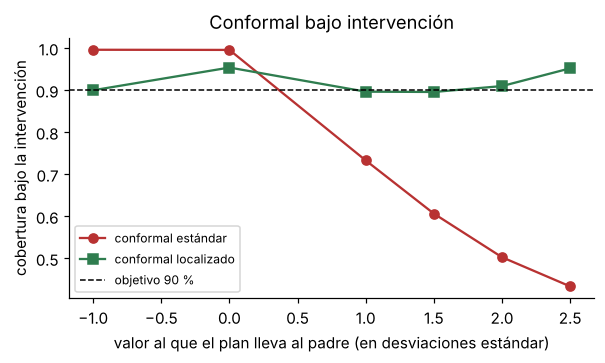

In [4]:
def localized_experiment(z_new, rng, n_fit=400, n_cal=600, n_test=4000, alpha=0.10, bw=0.3):
    """Mecanismo hijo = 2·padre + ruido cuyo tamaño CRECE con el padre.
    Un plan lleva al padre a z_new. ¿El intervalo cubre al hijo en ese punto?
    Compara conformal estándar con conformal localizado (pesa la calibración por cercanía a z_new)."""
    sd = lambda z: 0.5 + 0.8 * np.maximum(z, 0)
    sim = lambda z: 2 * z + sd(z) * rng.standard_normal(len(z))
    zf, zc = rng.standard_normal(n_fit), rng.standard_normal(n_cal)
    b = np.polyfit(zf, sim(zf), 1); s = np.abs(sim(zc) - np.polyval(b, zc))
    q_std = np.quantile(s, min(1, np.ceil((n_cal + 1) * (1 - alpha)) / n_cal))
    w = np.exp(-0.5 * ((zc - z_new) / bw) ** 2); order = np.argsort(s)             # cuantil ponderado
    cw = np.cumsum(np.r_[w[order], 1.0]) / (w.sum() + 1.0)                           # el punto nuevo cuenta con peso 1
    k = np.searchsorted(cw, 1 - alpha); q_loc = s[order][k] if k < n_cal else np.inf
    y = sim(np.full(n_test, z_new)); err = np.abs(y - np.polyval(b, z_new))          # el hijo bajo la INTERVENCIÓN
    return (err <= q_std).mean(), (err <= q_loc).mean(), q_std, q_loc, w.sum() ** 2 / (w ** 2).sum()

rng = np.random.default_rng(60)
print("valor del padre tras el plan | cobertura estándar | cobertura localizada | ancho estándar | ancho localizado | calibración efectiva")
zs = [-1.0, 0.0, 1.0, 1.5, 2.0, 2.5]; res = []
for z in zs:
    r = np.array([localized_experiment(z, rng) for _ in range(40)]); r = np.where(np.isinf(r), np.nan, r); m = np.nanmean(r, 0); res.append(m)
    print(f"          {z:+.1f}               |       {m[0]:.3f}        |        {m[1]:.3f}         |     ±{m[2]:.2f}      |      ±{m[3]:.2f}       |        {m[4]:.0f}")
res = np.array(res)
fig, ax = plt.subplots(figsize=(5.6, 3.4))
ax.plot(zs, res[:, 0], "o-", color="#B83232", label="conformal estándar"); ax.plot(zs, res[:, 1], "s-", color="#2F7D4F", label="conformal localizado")
ax.axhline(0.90, color="k", ls="--", lw=1, label="objetivo 90 %")
ax.set(xlabel="valor al que el plan lleva al padre (en desviaciones estándar)", ylabel="cobertura bajo la intervención", title="Conformal bajo intervención"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## 4 · El caso malo del buscador

**Qué hace.** En el cuaderno 02, un paciente de cinco quedó 9.6 % por encima del óptimo. Aquí se mide la brecha frente al óptimo de referencia en 12 pacientes con tres variantes del buscador.

**Literatura**
- Gelbart y otros (2014) y Astudillo y Frazier (2019), como en el cuaderno 01.

**Cómo leer el código.** `refine` es cuántas veces se añaden candidatos alrededor del mejor plan encontrado. El óptimo de referencia sale de una malla densa con la caja negra real y no cuenta como consultas.

**Qué mirar.** Brecha media, peor caso y cuántos casos pasan de 5 %.

In [5]:
rng = np.random.default_rng(70)
X_obs = sample_world(300, rng); graphs = bootstrap_graphs(X_obs, B=300, rng=rng); WORLDS = sample_worlds(X_obs, graphs, 100, rng); EPS = 0.10
def reference_cost(x):
    hs, bs = np.linspace(*H_RANGE, 121), np.linspace(*B_RANGE, 81); G = np.array([(h, b, k) for k in (0, 1) for h in hs for b in bs])
    r = np.concatenate([robust_margin(prob.blackbox().margin(counterfactual(x, WORLDS, G[i:i + 2000]).reshape(-1, 5)).reshape(-1, 100), EPS)[0]
                        for i in range(0, len(G), 2000)])
    return plan_cost(G[r >= 0]).min()
VARIANTS = [("como en el cuaderno 02 (1 refinamiento)", dict(refine=1)),
            ("3 refinamientos", dict(refine=3)),
            ("3 refinamientos + 60 pasos", dict(refine=3, n_iter=60))]
gaps = {nm: [] for nm, _ in VARIANTS}; qs = {nm: [] for nm, _ in VARIANTS}; t0 = time.time()
for i, x in enumerate(pick_patients(12, rng)):
    ref = reference_cost(x)
    for nm, kw in VARIANTS:
        bb = prob.blackbox(); pl, inf = solve_bo(prob, x, WORLDS, EPS, bb, seed=i, **kw)
        gaps[nm].append(np.nan if pl is None else 100 * (plan_cost(pl[None])[0] / ref - 1)); qs[nm].append(bb.n)
print(f"12 pacientes en {time.time() - t0:.0f} s. Brecha = cuánto más cuesta nuestro plan que el óptimo de referencia.\n")
print(f"{'variante del buscador':<42}{'brecha media':>13}{'brecha peor':>13}{'casos > 5 %':>13}{'consultas':>11}")
for nm, _ in VARIANTS:
    g = np.array(gaps[nm]); print(f"{nm:<42}{np.nanmean(g):>11.1f} %{np.nanmax(g):>11.1f} %{int(np.nansum(g > 5)):>10}/12{np.median(qs[nm]):>11.0f}")

12 pacientes en 402 s. Brecha = cuánto más cuesta nuestro plan que el óptimo de referencia.

variante del buscador                      brecha media  brecha peor  casos > 5 %  consultas
como en el cuaderno 02 (1 refinamiento)           0.0 %        1.5 %         0/12        149
3 refinamientos                                   0.0 %        6.1 %         1/12        149
3 refinamientos + 60 pasos                        0.0 %        5.7 %         1/12        169


## 5 · Más casos, con intervalo

**Qué hace.** Repite la comparación ingenuo contra robusto en 45 casos (15 conjuntos de datos × 3 pacientes) y reporta el éxito real con intervalo de Wilson.

**Qué mirar.** Si los intervalos de los dos métodos se separan, y si el del robusto es compatible con el 90 % pedido.

In [6]:
rows = []; t0 = time.time()
for d in range(15):                                       # 15 conjuntos de datos x 3 pacientes = 45 casos
    rng = np.random.default_rng(300 + d); X_obs = sample_world(300, rng); graphs = bootstrap_graphs(X_obs, B=200, rng=rng)
    W = sample_worlds(X_obs, graphs, 100, rng); Wp = make_worlds(fit_mechanisms(X_obs, graphs[0][0]))
    hs, bs = np.linspace(*H_RANGE, 61), np.linspace(*B_RANGE, 41); G = np.array([(h, b, k) for k in (0, 1) for h in hs for b in bs])
    for x in pick_patients(3, rng):
        m = prob.blackbox().margin(counterfactual(x, Wp, G)[:, 0, :]); nv = G[m >= 0][np.argmin(plan_cost(G[m >= 0]))]
        bb = prob.blackbox(); pl, inf = solve_bo(prob, x, W, 0.10, bb, n_iter=30, n_cand=800, seed=d, refine=3)
        rows.append((true_success(x, nv), plan_cost(nv[None])[0], np.nan if pl is None else true_success(x, pl), np.nan if pl is None else plan_cost(pl[None])[0]))
R = np.array(rows); n = len(R); ok = ~np.isnan(R[:, 2])
print(f"{n} casos en {time.time() - t0:.0f} s\n")
for nm, s, c, msk in [("ingenuo (una estimación)", R[:, 0], R[:, 1], np.ones(n, bool)), ("robusto por bootstrap, 90 %", R[:, 2], R[:, 3], ok)]:
    k = int(s[msk].sum()); lo, hi = wilson(k, msk.sum())
    print(f"{nm:<30} éxito real {k}/{msk.sum()} = {100 * k / msk.sum():.0f} %  (IC 95 %: {100 * lo:.0f} a {100 * hi:.0f} %) | costo medio {c[msk].mean():.3f}")

45 casos en 201 s

ingenuo (una estimación)       éxito real 32/45 = 71 %  (IC 95 %: 57 a 82 %) | costo medio 0.926
robusto por bootstrap, 90 %    éxito real 44/45 = 98 %  (IC 95 %: 88 a 100 %) | costo medio 0.927


## Estado después de los cuatro cuadernos

| Pieza | Estado |
|---|---|
| Motor contrafactual con bloqueo, validez robusta, BO compuesta, certificación, poda | Hecho (01) |
| Probabilidad de éxito por capas, preguntas Q1–Q5, frontera | Hecho (01, 02) |
| Varias semillas y pacientes con éxito real | Hecho (02, 04) |
| Garantía formal para grafo y mecanismos | Hecho para el caso lineal con orden conocido (02) |
| Líneas de base de consultas | Hecho (02) |
| Comparación contra Karimi et al. 2020 en su caso | Hecho, con su método reimplementado (03) |
| Mecanismos no lineales | Hecho (03) |
| Grafo sin orden dado | Hecho por búsqueda exacta para pocas variables (04) |
| Conformal bajo intervención | Comprobado en simulación para un mecanismo (04) |
| Cota por largo de camino | Enunciada y comprobada en el caso observacional (02) |
| Selección por valor p conformal | Hecho como puntaje (02) |

### Lo que sigue pendiente
1. **Unir las piezas:** conformal localizado dentro del plan (hoy está en una simulación aparte) y la capa del grafo dentro de la comparación del cuaderno 03.
2. **Teoría:** escribir y probar la cota por largo de camino bajo intervención, y las condiciones de la garantía por caja.
3. **Escala:** el descubrimiento exacto no pasa de unas 8 variables; para más hace falta un método aproximado.
4. **Datos reales** (German Credit, Adult, Sachs) y los otros casos de Karimi et al.
5. **Integrar `recourse_bo`** y repetir todo con varias semillas.